In [ ]:
# 🚀 Project 1 : Breast Cancer Prediction - CNN Model

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout


In [ ]:
# Extract Zip file
import zipfile
file = zipfile.ZipFile("brest_cancer.zip")
file.extractall()
file.close()

In [ ]:
!pip install split-folders

In [118]:
# Split the dataset into Two files for Training-80% & Testing-20%
import splitfolders
splitfolders.ratio("Dataset_BUSI_with_GT",output = "datas",seed = 42,ratio = (0.8, 0.2))

Copying files: 1578 files [00:04, 348.85 files/s]


In [119]:
# Train & Test The Datas
training_data = ImageDataGenerator(rescale=1.0/255)
train_data = training_data.flow_from_directory("/content/datas/train",
                                               target_size = (64, 64),
                                               batch_size = 16,
                                               class_mode = "categorical")

test_data = training_data.flow_from_directory("/content/datas/val",
                                              target_size = (64, 64),
                                              batch_size = 16,
                                              class_mode = "categorical")

Found 1260 images belonging to 3 classes.
Found 318 images belonging to 3 classes.


In [120]:
# Find the image shape
img = tf.keras.utils.load_img("/content/datas/train/benign/benign (1).png")
np.array(img).shape

(471, 562, 3)

In [122]:
# Train the CNN Model by using Relu & Softmax
model = tf.keras.models.Sequential()

model.add(tf.keras.layers.Conv2D(filters = 32, padding ="same",kernel_size = 3,activation="relu",input_shape = [64,64,3]))
model.add(tf.keras.layers.MaxPool2D(pool_size=2, strides=2))

model.add(tf.keras.layers.Conv2D(filters = 64,padding ="same",kernel_size = 3,activation ="relu",))
model.add(tf.keras.layers.MaxPool2D(pool_size=2, strides=2))

model.add(tf.keras.layers.Conv2D(filters = 128,padding ="same",kernel_size = 3,activation ="relu"))
model.add(tf.keras.layers.MaxPool2D(pool_size= 2, strides= 2))

model.add(tf.keras.layers.Flatten())

model.add(tf.keras.layers.Dense(units = 128 , activation = "relu"))
model.add(tf.keras.layers.Dropout(0.5))
model.add(tf.keras.layers.Dense(units = 3 , activation = "softmax"))


In [123]:
model.summary()

Model: "sequential_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_17 (Conv2D)              │ (None, 64, 64, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_16 (MaxPooling2D) │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_18 (Conv2D)              │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_17 (MaxPooling2D) │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_19 (Conv2D)              │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_18 (MaxPooling2D) │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_7 (Flatten)             │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 128)            │     1,048,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,142,339 (4.36 MB)

 Trainable params: 1,142,339 (4.36 MB)

 Non-trainable params: 0 (0.00 B)

In [135]:
# Compile The Model
model.compile(optimizer = "adam", loss = "categorical_crossentropy", metrics = ["accuracy"])

In [136]:
# Find The accuracy & loss to use Model Fit
CNN = model.fit(train_data, validation_data = test_data, epochs = 5)
print(CNN)

Epoch 1/5
79/79 ━━━━━━━━━━━━━━━━━━━━ 27s 323ms/step - accuracy: 0.7841 - loss: 0.4900 - val_accuracy: 0.7484 - val_loss: 0.6139
Epoch 2/5
79/79 ━━━━━━━━━━━━━━━━━━━━ 25s 314ms/step - accuracy: 0.8056 - loss: 0.4405 - val_accuracy: 0.7862 - val_loss: 0.5924
Epoch 3/5
79/79 ━━━━━━━━━━━━━━━━━━━━ 24s 308ms/step - accuracy: 0.8540 - loss: 0.3615 - val_accuracy: 0.8145 - val_loss: 0.6048
Epoch 4/5
79/79 ━━━━━━━━━━━━━━━━━━━━ 42s 316ms/step - accuracy: 0.8762 - loss: 0.3274 - val_accuracy: 0.8082 - val_loss: 0.5322
Epoch 5/5
79/79 ━━━━━━━━━━━━━━━━━━━━ 25s 313ms/step - accuracy: 0.8881 - loss: 0.2976 - val_accuracy: 0.8082 - val_loss: 0.4689


In [137]:
# To Find Model Accuracy & Loss By Model Evaluate
loss , accuracy = model.evaluate(test_data)

print("Accuracy : ", accuracy)
print("Loss     : ", loss)

20/20 ━━━━━━━━━━━━━━━━━━━━ 3s 128ms/step - accuracy: 0.8082 - loss: 0.4689
Accuracy :  0.8081761002540588
Loss     :  0.4689253270626068


In [139]:
# Testing by new images
class_names = train_data.class_indices
img = tf.keras.utils.load_img("breast_image.png", target_size = (64,64))
img = tf.keras.utils.img_to_array(img)
img = img/255.0
img = np.expand_dims(img, axis = 0)
results = model.predict(img)
result = results[0]
print(result)
print(class_names)


<PIL.Image.Image image mode=RGB size=64x64 at 0x79FF66E72950>
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
[0.56761515 0.431356   0.00102888]
{'benign': 0, 'malignant': 1, 'normal': 2}


In [140]:
# Final Prediction of Breast Cancer Applying By CNN Model

pre_index = np.argmax(result)
classes_list = list(class_names.keys())
pre_class = classes_list[pre_index]
confidence = result[pre_index]

print("prediction Index :", pre_index)
print("prediction Class :", pre_class)
print("confidence       :", confidence)

if pre_class == "malignant":
  print("\nResult : Cancer Detected !")
elif pre_class == "benign":
  print("\nResult : Not cancer, but abnormal/non-cancerous tumor")
else:
  print("\nResult : Normal ! No Cancer Detected")

prediction Index : 0
prediction Class : benign
confidence       : 0.56761515

Result : Not cancer, but abnormal/non-cancerous tumor


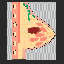

In [148]:
# New Testing Image Shown
from tensorflow.keras.preprocessing import image
imge = image.load_img("breast_image.png", target_size = (64,64))
imge

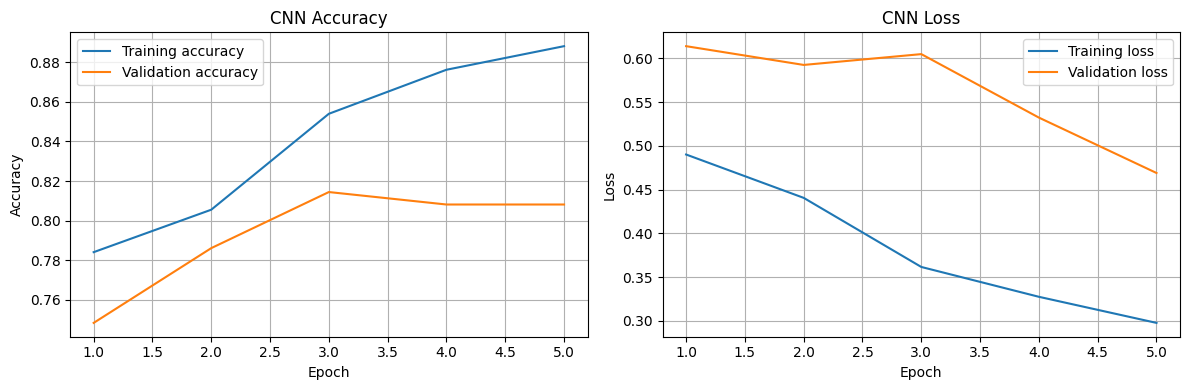

In [141]:
# Plot a Accuracy & Loss in a Graph
import matplotlib.pyplot as plt

history = CNN
acc = history.history["accuracy"]
val_acc = history.history["val_accuracy"]
loss = history.history["loss"]
val_loss = history.history["val_loss"]
epochs = range(1, len(acc) + 1)

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(epochs, acc, label="Training accuracy")
plt.plot(epochs, val_acc, label="Validation accuracy")
plt.title("CNN Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(epochs, loss, label="Training loss")
plt.plot(epochs, val_loss, label="Validation loss")
plt.title("CNN Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.savefig("training_graphs.png", dpi=300)
plt.show()